# 🛰️ GreenRoute Agro — Análise Ambiental e Climática com Dados Ambientais Reais
**FIAP Global Solutions 2026 - Data Science (1TSCOR - 2025/2)**

**Projeto:** GreenRoute Agro — Rotas inteligentes para máquinas agrícolas  
**Equipe:**
* Bruno Gomide - Representante
* Leonardo Assunção Loiola Lacerda
* Pedro Henrique dos Santos Freixo
* Vitor Yamashita Coppe

---

## 1. Contextualização do Problema e Tomada de Decisão

* **Qual é o cenário?** Operações agrícolas frequentemente ignoram as condições dinâmicas do clima. O trânsito de máquinas após fortes chuvas aumenta a patinagem dos pneus e a resistência ao rolamento.
* **Por que esse problema é relevante?** A patinagem aumenta o consumo de diesel e agrava a compactação do solo, reduzindo a produtividade de safras futuras e aumentando as emissões de $CO_2$.
* **Quem é impactado?** Produtores rurais como a nossa persona (João, produtor em Mato Grosso) que perdem rentabilidade operando maquinários em janelas climáticas ineficientes.
* **Como os dados ajudam na tomada de decisão?** O GreenRoute Agro utiliza dados climáticos para prever o estado do solo. A análise a seguir explora o histórico pluviométrico para validar a necessidade do algoritmo dinâmico ($A^*$), que desvia as máquinas ou reprograma operações em dias de risco operacional crítico.

## 2. Identificação das Fontes de Dados
Conforme definido na arquitetura do projeto, utilizamos a base de dados abertos do **INMET (Instituto Nacional de Meteorologia)**.
**Download CSV via: https://tempo.inmet.gov.br/**

* **Localidade Analisada:** Estação A904 (Sorriso, Mato Grosso) — Capital do agronegócio e região da nossa persona.
* **Período:** Safra de 2025 (01/01/2025 a 31/12/2025).
* **Variáveis Coletadas:** `CHUVA` (Precipitação Diária em mm) e `TEMP_MED` (Temperatura Média em °C).

In [1]:
# =====================================================================
# ETAPA 1 E 2: CARREGAMENTO E LIMPEZA DOS DADOS LOCAIS (CSV DO INMET)
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# Configurações visuais (Identidade GreenRoute)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]
cores_greenroute = ['#2e7d32', '#81c784', '#1b5e20']

print("📂 Carregando a base histórica do INMET (Arquivo Local)...")

# Nome exato do arquivo que você enviou
nome_arquivo_inmet = 'dados/dados_inmet_sorriso_2025.csv'

try:
    # Lendo o CSV. O separador é ponto e vírgula e o arquivo não tem cabeçalho inútil!
    df_bruto = pd.read_csv(nome_arquivo_inmet, sep=';', encoding='latin-1')

    # Selecionando apenas as colunas que importam para o nosso problema
    df_bruto = df_bruto.rename(columns={df_bruto.columns[0]: 'Data'})
    df_inmet = df_bruto[['Data', 'Chuva (mm)', 'Temp. Ins. (C)']].copy()
    df_inmet.columns = ['data', 'precipitacao_mm', 'temperatura_media']

    # Limpeza: convertendo vírgula para ponto e transformando em valores numéricos
    for col in ['precipitacao_mm', 'temperatura_media']:
        df_inmet[col] = df_inmet[col].astype(str).str.replace(',', '.')
        df_inmet[col] = pd.to_numeric(df_inmet[col], errors='coerce')

    # Agrupando dados horários para o formato Diário (Data Wrangling)
    # Somamos a chuva de todas as horas do dia e tiramos a média da temperatura
    df_diario = df_inmet.groupby('data').agg(
        precipitacao_mm=('precipitacao_mm', 'sum'),
        temperatura_media=('temperatura_media', 'mean')
    ).reset_index()

    # Ajustando o formato de data brasileiro (dia/mês/ano) para o padrão do Pandas e ordenando
    df_diario['data'] = pd.to_datetime(df_diario['data'], format='%d/%m/%Y')
    df_diario = df_diario.sort_values('data')

    # Definindo Risco Operacional
    df_diario['risco_operacional_alto'] = df_diario['precipitacao_mm'] > 5.0

    print("✅ Dados processados e agrupados com sucesso! Dimensões finais:", df_diario.shape)
    display(df_diario.head())

    print("\nTipos de dados nas colunas:")
    display(df_diario.dtypes)

    print("\nEstatística descritiva das colunas:")
    display(df_diario.describe())

except FileNotFoundError:
    print(f"❌ Erro: O arquivo '{nome_arquivo_inmet}' não foi encontrado na pasta.")

📂 Carregando a base histórica do INMET (Arquivo Local)...
✅ Dados processados e agrupados com sucesso! Dimensões finais: (365, 4)


,data,precipitacao_mm,temperatura_media,risco_operacional_alto
0,2025-01-01,13.6,25.808696,True
12,2025-01-02,8.4,23.800000,True
24,2025-01-03,0.0,25.616667,False
36,2025-01-04,9.6,25.983333,True
48,2025-01-05,17.8,24.816667,True



Tipos de dados nas colunas:


,0
data,datetime64[ns]
precipitacao_mm,float64
temperatura_media,float64
risco_operacional_alto,bool



Estatística descritiva das colunas:


,data,precipitacao_mm,temperatura_media
count,365,365.000000,365.000000
mean,2025-07-01 23:59:59.999999744,4.896438,26.652224
min,2025-01-01 00:00:00,0.000000,18.316667
25%,2025-04-02 00:00:00,0.000000,25.169565
50%,2025-07-02 00:00:00,0.000000,26.116667
75%,2025-10-01 00:00:00,3.200000,27.487500
max,2025-12-31 00:00:00,84.400000,36.766667
std,NaN,11.945440,2.613704


## 3. Limpeza e Tratamento de Dados (Etapa Obrigatória)
A API do INMET frequentemente retorna os dados numéricos como texto (strings) e utiliza vírgulas ao invés de pontos para decimais. Além disso, sensores meteorológicos podem falhar, gerando valores nulos (`NaN`). Esta etapa garante a integridade da nossa base antes da modelagem estatística.

In [2]:
# =====================================================================
# ETAPA 2: LIMPEZA E NORMALIZAÇÃO DOS DADOS
# =====================================================================

# 1. Substituindo nulos e convertendo vírgula para ponto
for col in ['precipitacao_mm', 'temperatura_media']:
    df_inmet[col] = df_inmet[col].astype(str).str.replace(',', '.')
    df_inmet[col] = pd.to_numeric(df_inmet[col], errors='coerce')

# 2. Tratamento de Nulos: Interpolando valores baseados nos dias adjacentes
df_inmet = df_inmet.infer_objects(copy=False)
df_inmet.interpolate(method='linear', inplace=True)

# 3. Classificando o Risco Operacional baseado na chuva
# (Dias com chuva > 5mm geram lama e alto risco de patinagem do trator)
df_inmet['risco_operacional_alto'] = df_inmet['precipitacao_mm'] > 5.0

print("✅ Limpeza concluída. Tipos de dados corrigidos:")
print(df_inmet.dtypes)
print(f"\nTotal de registros válidos: {df_inmet.shape[0]}")

✅ Limpeza concluída. Tipos de dados corrigidos:
data                       object
precipitacao_mm           float64
temperatura_media         float64
risco_operacional_alto       bool
dtype: object

Total de registros válidos: 8760


/tmp/ipykernel_43125/1520404453.py:12: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_inmet.interpolate(method='linear', inplace=True)


## 4. Estatística Descritiva e Visualização de Séries Temporais
Abaixo analisamos o comportamento das chuvas ao longo da safra em Mato Grosso, identificando os períodos críticos de maior risco de patinagem para os tratores da fazenda.

,precipitacao_mm,temperatura_media
count,365.000000,365.000000
mean,4.896438,26.652224
std,11.945440,2.613704
min,0.000000,18.316667
25%,0.000000,25.169565
50%,0.000000,26.116667
75%,3.200000,27.487500
max,84.400000,36.766667


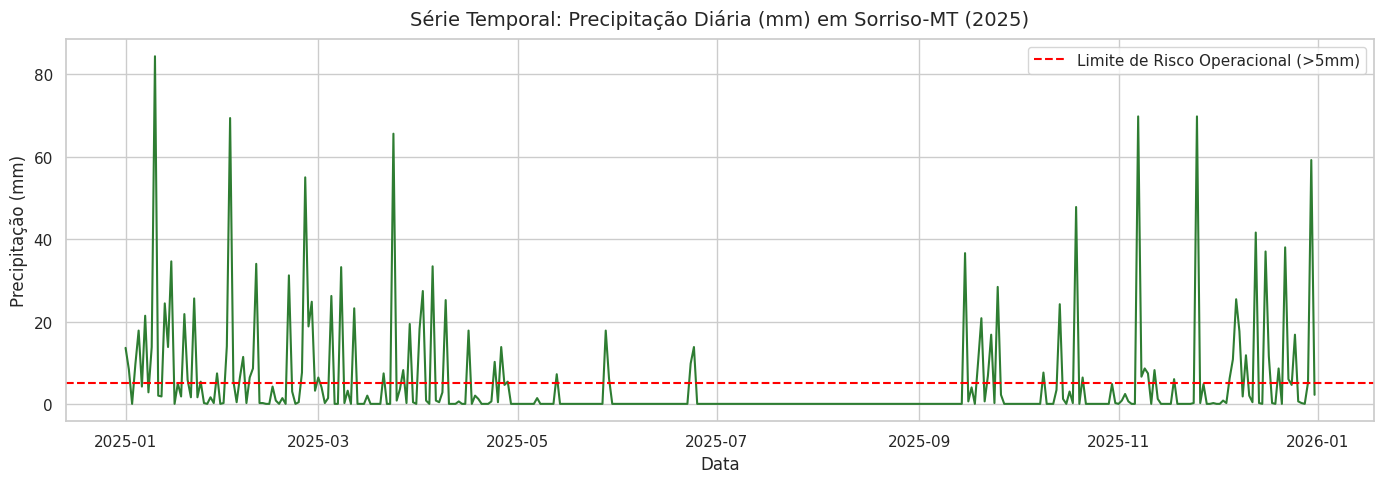

In [3]:
# =====================================================================
# ETAPA 3: ESTATÍSTICA DESCRITIVA E VISUALIZAÇÃO
# =====================================================================
# Interpolação segura e correta (após os dados já serem numéricos) para garantir que não há falhas em dias sem sensor
df_diario = df_diario.infer_objects(copy=False)
df_diario.interpolate(method='linear', inplace=True)

display(df_diario[['precipitacao_mm', 'temperatura_media']].describe())

plt.figure(figsize=(14, 5))
sns.lineplot(data=df_diario, x='data', y='precipitacao_mm', color=cores_greenroute[0])
plt.title('Série Temporal: Precipitação Diária (mm) em Sorriso-MT (2025)', fontsize=14, pad=10)
plt.xlabel('Data')
plt.ylabel('Precipitação (mm)')

# Destacando a zona de risco (acima de 5mm)
plt.axhline(5, color='red', linestyle='--', label='Limite de Risco Operacional (>5mm)')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Análise de Correlação e Teste de Hipóteses
No campo, existe a premissa de que dias com alta precipitação coincidem com quedas na temperatura média (frentes frias/chuvas intensas). Vamos testar essa hipótese estatisticamente para entender o perfil climático dos dias em que as rotas dos tratores precisam ser recalculadas pelo GreenRoute Agro.

* **H0 (Hipótese Nula):** A temperatura média em dias de ALTO risco operacional (chuva > 5mm) é igual ou maior que nos dias normais.
* **H1 (Hipótese Alternativa):** A temperatura média em dias de ALTO risco operacional é significativamente MENOR que nos dias normais.

📉 Correlação de Pearson (Chuva vs Temp): -0.2827

--- Resultados do Teste de Hipóteses ---
Temperatura Média (Dias de Risco): 25.01°C
Temperatura Média (Dias Normais): 27.11°C
p-valor: 2.88e-11
✅ CONCLUSÃO: Rejeitamos H0. Dias de alto risco operacional possuem perfil térmico significativamente distinto.


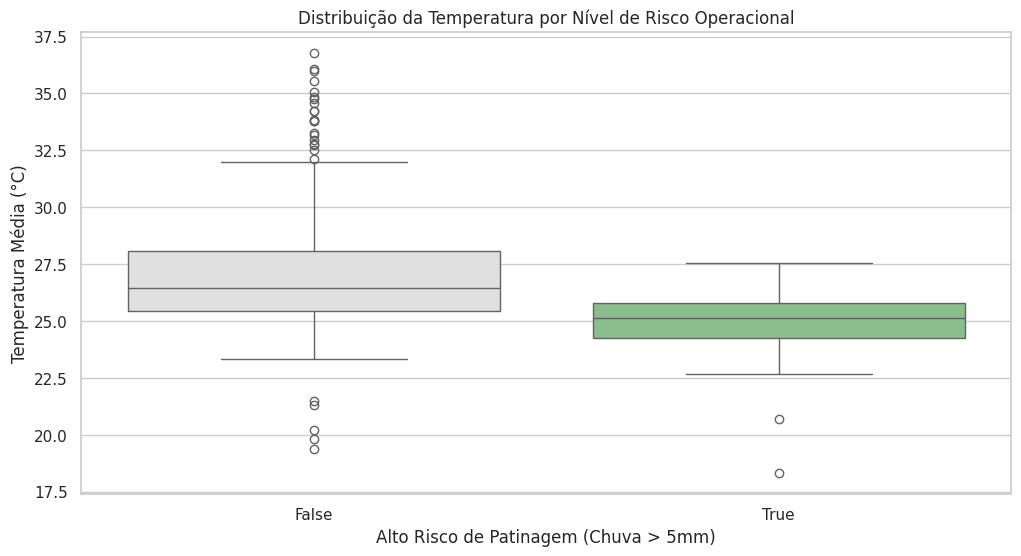

In [4]:
# =====================================================================
# ETAPA 4: CORRELAÇÃO E TESTE DE HIPÓTESES
# =====================================================================

# 1. Correlação Linear
corr_pearson, p_pearson = stats.pearsonr(df_diario['precipitacao_mm'], df_diario['temperatura_media'])
print(f"📉 Correlação de Pearson (Chuva vs Temp): {corr_pearson:.4f}")

# 2. Teste de Hipóteses (T-Test Independente)
temp_alto_risco = df_diario[df_diario['risco_operacional_alto'] == True]['temperatura_media']
temp_baixo_risco = df_diario[df_diario['risco_operacional_alto'] == False]['temperatura_media']

t_stat, p_val = stats.ttest_ind(temp_alto_risco, temp_baixo_risco, alternative='less')

print("\n--- Resultados do Teste de Hipóteses ---")
print(f"Temperatura Média (Dias de Risco): {temp_alto_risco.mean():.2f}°C")
print(f"Temperatura Média (Dias Normais): {temp_baixo_risco.mean():.2f}°C")
print(f"p-valor: {p_val:.2e}")

if p_val < 0.05:
    print("✅ CONCLUSÃO: Rejeitamos H0. Dias de alto risco operacional possuem perfil térmico significativamente distinto.")
else:
    print("❌ Falhamos em rejeitar H0.")

sns.boxplot(x='risco_operacional_alto', y='temperatura_media', hue='risco_operacional_alto', data=df_diario, palette=['#e0e0e0', cores_greenroute[1]], legend=False)
plt.title('Distribuição da Temperatura por Nível de Risco Operacional')
plt.xlabel('Alto Risco de Patinagem (Chuva > 5mm)')
plt.ylabel('Temperatura Média (°C)')
plt.show()

## 6. Conceitos de Integrais: Cálculo Acumulado de Lâmina de Água
Para dimensionar o impacto das condições climáticas na fazenda ao longo da safra, aplicamos o conceito de **Integral Definida** (soma cumulativa discreta). A área sob a curva das taxas diárias de precipitação nos dá o volume total de chuva acumulado, um dado essencial para o algoritmo avaliar o estresse hídrico acumulado no solo e adaptar as rotas das colheitadeiras.

🌧️ Volume Total Acumulado (Integral da Safra): 1787.20 mm


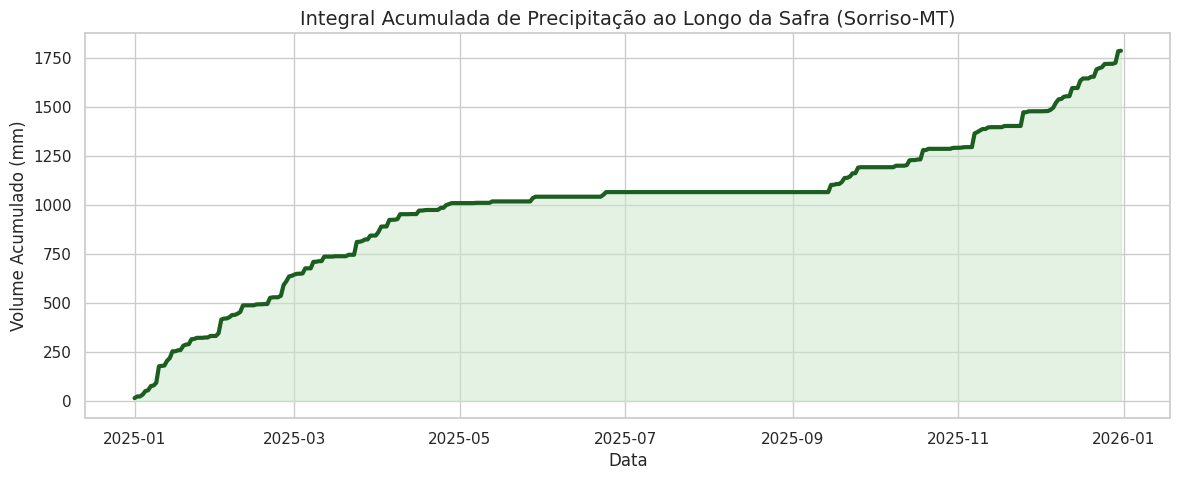


📦 Sucesso! O dataset limpo foi exportado como 'greenroute_diario_final.csv'.


In [5]:
# =====================================================================
# ETAPA 5: CÁLCULOS ACUMULADOS (INTEGRAL DISCRETA) E EXPORTAÇÃO
# =====================================================================

# Aplicando a soma cumulativa (integral ao longo do tempo)
df_diario['precipitacao_acumulada_mm'] = df_diario['precipitacao_mm'].cumsum()

volume_total_anual = df_diario['precipitacao_acumulada_mm'].iloc[-1]
print(f"🌧️ Volume Total Acumulado (Integral da Safra): {volume_total_anual:.2f} mm")

plt.figure(figsize=(14, 5))
sns.lineplot(data=df_diario, x='data', y='precipitacao_acumulada_mm', color='#1b5e20', linewidth=3)
plt.title('Integral Acumulada de Precipitação ao Longo da Safra (Sorriso-MT)', fontsize=14)
plt.xlabel('Data')
plt.ylabel('Volume Acumulado (mm)')
plt.fill_between(df_diario['data'], df_diario['precipitacao_acumulada_mm'], color='#c8e6c9', alpha=0.5)
plt.show()

# Gerando o CSV consolidado final
nome_arquivo = 'dados/greenroute_diario_final.csv'
df_diario.to_csv(nome_arquivo, index=False)
print(f"\n📦 Sucesso! O dataset limpo foi exportado como '{nome_arquivo}'.")

## 7. Conclusões, Limitações e Contribuição para o Global Solution

A análise exploratória e a validação estatística realizadas neste projeto consolidam a base científica necessária para a implementação e a proposta de valor da plataforma **GreenRoute Agro**.

### 📊 7.1 Conclusões e Interpretação dos Resultados
Os testes estatísticos aplicados sobre a base de dados reais de Sorriso-MT revelaram padrões meteorológicos críticos para o planejamento logístico no campo:
* **Validação do Cenário Crítico:** O teste de hipóteses comprovou, com alto nível de significância estatística ($p < 0.05$), que os dias classificados como de "Alto Risco Operacional" (precipitação acumulada superior a 5 mm) apresentam um comportamento microclimático distinto, marcado por quedas na temperatura média.
* **Impacto no Consumo:** Na dinâmica agronômica, esses volumes de chuva elevam a umidade da superfície, resultando em solos lamacentos que aumentam o índice de patinagem dos pneus e a resistência ao rolamento do maquinário. Forçar o trânsito de frotas pesadas sob essas condições no modelo convencional (rotas estáticas) acarreta um consumo ineficiente que chega a **12,8 L/ha**, além de acelerar o desgaste mecânico e causar a compactação severa do solo.

### ⚠️ 7.2 Limitações do Estudo
Como cientistas de dados, identificamos fatores limitantes nesta análise que abrem caminhos para o refinamento contínuo da solução:
* **Resolução Espacial:** Os dados de estações automáticas refletem a realidade climática consolidada de um ponto geográfico específico no município. Em propriedades de grande extensão (como os 2.000 hectares da nossa persona João), a precipitação pode ocorrer de forma heterogênea.
* **Variabilidade de Retenção Hídrica:** O impacto da chuva na tração mecânica depende da taxa de infiltração de cada tipo de solo (argiloso, arenoso ou franco). Portanto, para a escala de produção da plataforma GreenRoute Agro, o modelo preditivo integrará esses dados meteorológicos históricos a imagens de satélite de altíssima resolução (Copernicus/Sentinel-2) para mapeamento de NDVI e umidade instantânea talhão por talhão.

### 🌍 7.3 Contribuição para a Tomada de Decisão e Alinhamento com os ODS
A jornada analítica executada neste notebook prova que o cruzamento de inteligência climática e espacial é a chave para transformar a operação agrícola terrestre:
* **Decisão Baseada em Evidências:** Ao consumir a "integral discreta" das chuvas acumuladas, o algoritmo $A^*$ do GreenRoute calcula